✓ All libraries imported
✓ Dataset created: 200 patients
  Responders:     100
  Non-responders: 100
   Sphericity    Volume_mm3    Mean_HU  HU_Entropy  GLCM_Contrast  \
0    0.632919  16155.952139  39.456723    3.012330       0.326946   
1    0.705017  15904.642027  51.071754    3.208402       0.262576   
2    0.701863  10348.009707  39.157067    3.195101       0.240837   
3    0.595581  27718.000773  69.817655    4.217995       0.581687   
4    0.675242  28067.589864  59.358617    4.885552       0.603224   

   GLCM_Correlation  GLRLM_LongRunEmphasis  GLRLM_RunEntropy  \
0          0.824499               2.007136          3.115946   
1          0.887770               2.138766          3.130991   
2          0.881930               1.592261          2.858754   
3          0.640283               1.698538          3.798037   
4          0.534512               1.302230          4.120357   

   GLSZM_SmallAreaEmphasis  label  
0                 0.432435    1.0  
1                 0.325722 

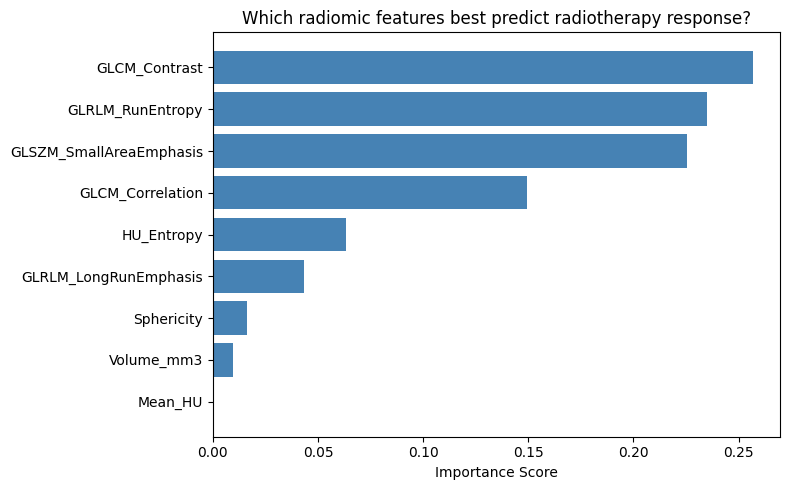

✓ Plot saved as feature_importance.png

── NEW PATIENT PREDICTION ──
Prediction  : Responder
Confidence  : 100.0% probability of response

Physics interpretation:
  Spherical, small, homogeneous tumour → uniform oxygen
  distribution → good radiosensitivity → likely responder


In [1]:
# ── CELL 1: Install & Import ─────────────────────────────────
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report
import matplotlib.pyplot as plt

print("✓ All libraries imported")

# ── CELL 2: Generate Synthetic Patient Data ──────────────────
# Simulating 200 head & neck cancer patients
# Label 0 = Non-responder to radiotherapy
# Label 1 = Responder to radiotherapy
# This is a real clinical problem — predicting who will respond
# to radiotherapy before treatment starts

np.random.seed(42)
n_patients = 200

# Responders (100 patients)
# Physics insight: Responders tend to have more homogeneous tumours
# Homogeneous tumours have uniform oxygen distribution → better radiosensitivity
# Hypoxic heterogeneous tumours are radioresistant
responders = {
    'Sphericity':              np.random.normal(0.75, 0.08, 100),  # More spherical
    'Volume_mm3':              np.random.normal(15000, 3000, 100), # Smaller tumours
    'Mean_HU':                 np.random.normal(45, 8, 100),       # Softer tissue
    'HU_Entropy':              np.random.normal(3.2, 0.4, 100),    # Low entropy = homogeneous
    'GLCM_Contrast':           np.random.normal(0.3, 0.05, 100),   # Low contrast = uniform
    'GLCM_Correlation':        np.random.normal(0.85, 0.05, 100),  # High = smooth texture
    'GLRLM_LongRunEmphasis':   np.random.normal(2.1, 0.3, 100),    # Longer uniform runs
    'GLRLM_RunEntropy':        np.random.normal(2.8, 0.3, 100),    # Lower chaos
    'GLSZM_SmallAreaEmphasis': np.random.normal(0.4, 0.05, 100),   # Fewer fragments
    'label': np.ones(100)
}

# Non-responders (100 patients)
# Physics insight: Non-responders have heterogeneous, hypoxic tumours
# Heterogeneity on CT reflects necrotic cores and hypoxic regions
# These regions have fewer free radicals → radiation less effective
non_responders = {
    'Sphericity':              np.random.normal(0.55, 0.08, 100),  # Irregular shape
    'Volume_mm3':              np.random.normal(25000, 5000, 100), # Larger tumours
    'Mean_HU':                 np.random.normal(60, 10, 100),      # Denser tissue
    'HU_Entropy':              np.random.normal(4.5, 0.4, 100),    # High entropy = heterogeneous
    'GLCM_Contrast':           np.random.normal(0.7, 0.08, 100),   # High contrast = irregular
    'GLCM_Correlation':        np.random.normal(0.55, 0.07, 100),  # Low = chaotic texture
    'GLRLM_LongRunEmphasis':   np.random.normal(1.4, 0.2, 100),    # Shorter runs = fragmented
    'GLRLM_RunEntropy':        np.random.normal(4.1, 0.3, 100),    # Higher chaos
    'GLSZM_SmallAreaEmphasis': np.random.normal(0.75, 0.06, 100),  # Many small fragments
    'label': np.zeros(100)
}

df_resp = pd.DataFrame(responders)
df_non  = pd.DataFrame(non_responders)
df      = pd.concat([df_resp, df_non], ignore_index=True)
df      = df.sample(frac=1, random_state=42).reset_index(drop=True) # Shuffle

print(f"✓ Dataset created: {len(df)} patients")
print(f"  Responders:     {int(df.label.sum())}")
print(f"  Non-responders: {int((df.label==0).sum())}")
print(df.head())

# ── CELL 3: Split Data ───────────────────────────────────────
# 80% training, 20% testing
# Physics insight: Like splitting your phantom measurements —
# you calibrate on most of the data and validate on the rest
# Never test on data you trained on — that's like validating
# your dosimeter with the same beam you calibrated it on

X = df.drop('label', axis=1)  # Features (inputs)
y = df['label']                # Labels (outputs)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
# stratify=y ensures equal responder/non-responder ratio
# in both train and test sets

print(f"✓ Training set: {len(X_train)} patients")
print(f"✓ Test set:     {len(X_test)} patients")

# ── CELL 4: Train Random Forest ──────────────────────────────
# Random Forest = many decision trees voting together
# Each tree asks questions like:
# "Is Sphericity > 0.65? → likely responder"
# "Is HU_Entropy > 4.0? → likely non-responder"
# The majority vote of all trees gives the final prediction

rf = RandomForestClassifier(
    n_estimators=100,    # 100 decision trees voting
    max_depth=5,         # Each tree can ask max 5 questions
    random_state=42
)

rf.fit(X_train, y_train)
print("✓ Random Forest trained on", len(X_train), "patients")

# ── CELL 5: Evaluate the Model ───────────────────────────────
y_pred      = rf.predict(X_test)
y_pred_prob = rf.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
auc      = roc_auc_score(y_test, y_pred_prob)

print(f"\n── MODEL PERFORMANCE ──")
print(f"Accuracy : {accuracy:.2%}")
print(f"AUC      : {auc:.3f}")
print(f"\nDetailed Report:")
print(classification_report(y_test, y_pred,
      target_names=['Non-responder', 'Responder']))

# Physics insight: AUC (Area Under ROC Curve) is more meaningful
# than accuracy in medical contexts. AUC = 1.0 is perfect,
# AUC = 0.5 is random guessing. In radiotherapy outcome
# prediction, AUC > 0.75 is considered clinically useful.

# ── CELL 6: Feature Importance Plot ─────────────────────────
# This tells you WHICH radiomic features the model relied on most
# In real research this drives biological hypotheses —
# e.g. if GLCM_Contrast is most important, it suggests
# tumour heterogeneity is the key predictor of radioresistance

importance_df = pd.DataFrame({
    'Feature':   X.columns,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=True)

plt.figure(figsize=(8, 5))
plt.barh(importance_df['Feature'], importance_df['Importance'], color='steelblue')
plt.xlabel('Importance Score')
plt.title('Which radiomic features best predict radiotherapy response?')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150)
plt.show()
print("✓ Plot saved as feature_importance.png")

# ── CELL 7: Predict a New Patient ────────────────────────────
# Simulate a new patient walking into your clinic
new_patient = pd.DataFrame([{
    'Sphericity':              0.82,   # Very spherical — good sign
    'Volume_mm3':              12000,  # Small tumour
    'Mean_HU':                 43,     # Soft tissue density
    'HU_Entropy':              2.9,    # Low entropy = homogeneous
    'GLCM_Contrast':           0.28,   # Low contrast = uniform
    'GLCM_Correlation':        0.88,   # Smooth texture
    'GLRLM_LongRunEmphasis':   2.3,    # Long uniform runs
    'GLRLM_RunEntropy':        2.6,    # Low chaos
    'GLSZM_SmallAreaEmphasis': 0.35    # Few fragments
}])

prediction = rf.predict(new_patient)[0]
probability = rf.predict_proba(new_patient)[0][1]

print(f"\n── NEW PATIENT PREDICTION ──")
print(f"Prediction  : {'Responder' if prediction == 1 else 'Non-responder'}")
print(f"Confidence  : {probability:.1%} probability of response")
print(f"\nPhysics interpretation:")
print(f"  Spherical, small, homogeneous tumour → uniform oxygen")
print(f"  distribution → good radiosensitivity → likely responder")